# 01 · Load and explore the ticket data

**Goal of this notebook:** read the raw ticket file, understand it, check its quality, and store it in the **database**
so every later notebook can use SQL on it. By default this is a local **SQLite** file (zero setup); set `USE_MYSQL=1` in `.env` to use **MySQL** instead - the notebooks work with both.

**What a row is:** one e-ticket sold on a Delhi bus (ONDC e-ticketing), October 2026.

| Column | Meaning |
|---|---|
| `passenger_count` | people covered by this ticket |
| `route` | route **and direction**, e.g. `8UP`, `8DOWN` |
| `start_stop_name`, `end_stop_name` | where the passenger boarded / got off (typed names, sometimes messy) |
| `vehicle_number` | the bus - **missing on about half the rows** |
| `created_at` | time the ticket was issued |
| `is_ac` | AC bus or not |

In [1]:
# --- Setup: run this cell first ---------------------------------------------------------------
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))        # lets the notebook find config.py and the src/ folder
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config
from src import db

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30, "display.width", 140)

print("Data mode:", config.MODE.upper(), "| database:", config.DB_NAME if config.USE_MYSQL else "SQLite file")

from src import tickets
from src.tickets import detect_offdays

Data mode: REAL | database: SQLite file


## 1. Read the CSV with pandas

In [2]:
df = tickets.load_tickets_csv()      # reads data/raw/tickets.csv and cleans types (see src/tickets.py)
print(f"{len(df):,} tickets")
df.head()

2,559,899 tickets


,pax,amount,vehicle,ttype,start_name,end_name,route_raw,ts,is_ac,date,hour,dow,daytype
0,1,22.0,NaN,1,Ali Village,Mahamaya Flyover West,8UP,2026-10-28 10:19:18,1,2026-10-28,10,2,weekday
1,1,9.0,DL1PD6826,1,Kalindi Kunj Bdr,Crown Plaza,8ADOWN,2026-10-28 10:19:29,1,2026-10-28,10,2,weekday
2,1,13.5,DL51EV9760,1,Andrews Ganj,Clal Chowk,433UP,2026-10-28 10:19:46,1,2026-10-28,10,2,weekday
3,1,13.5,NaN,1,West Patel Nagar,Ice Factory,208DOWN,2026-10-28 10:19:47,1,2026-10-28,10,2,weekday
4,1,9.0,DL51EV9810,1,Chhatarpur Extension,Mallu Farm,516UP,2026-10-28 10:19:48,1,2026-10-28,10,2,weekday


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2559899 entries, 0 to 2559898
Data columns (total 13 columns):
 #   Column      Dtype         
---  ------      -----         
 0   pax         int64         
 1   amount      float64       
 2   vehicle     category      
 3   ttype       category      
 4   start_name  category      
 5   end_name    category      
 6   route_raw   category      
 7   ts          datetime64[us]
 8   is_ac       int64         
 9   date        str           
 10  hour        int32         
 11  dow         int32         
 12  daytype     str           
dtypes: category(5), datetime64[us](1), float64(1), int32(2), int64(2), str(2)
memory usage: 201.5 MB


## 2. Quality checks
Before using any dataset we ask: how much is missing, are there duplicates, what is the date range?

In [4]:
print("Date range      :", df.ts.min(), "->", df.ts.max())
print("Days in data    :", df.date.nunique())
print("Duplicate rows  :", df.duplicated().sum(), "(see note below)")
print("Distinct routes :", df.route_raw.nunique(), "| distinct vehicles:", df.vehicle.nunique())
print()
missing = df.isna().mean().mul(100).round(2).rename("% missing").to_frame()
missing

Date range      : 2026-10-01 00:00:01 -> 2026-10-31 23:58:22
Days in data    : 31


Duplicate rows  : 749 (see note below)
Distinct routes : 2259 | distinct vehicles: 6809



,% missing
pax,0.00
amount,0.00
vehicle,48.52
ttype,0.00
start_name,0.00
end_name,0.00
route_raw,0.00
ts,0.00
is_ac,0.00
date,0.00


> **Note on the "duplicate rows":** the raw file has *no* exact duplicates (its timestamps include microseconds). Our cleaned `ts` is cut to whole seconds, so a few hundred
> tickets issued in the same second on the same route now look identical. They are genuine tickets, so we keep them.

**Finding 1 - `vehicle` is missing on roughly half of the tickets.**
Our first idea was "group each bus's tickets into trips". Section 6 shows why we can still use these tickets,
and notebook 03 shows why we do not rebuild trips at all.

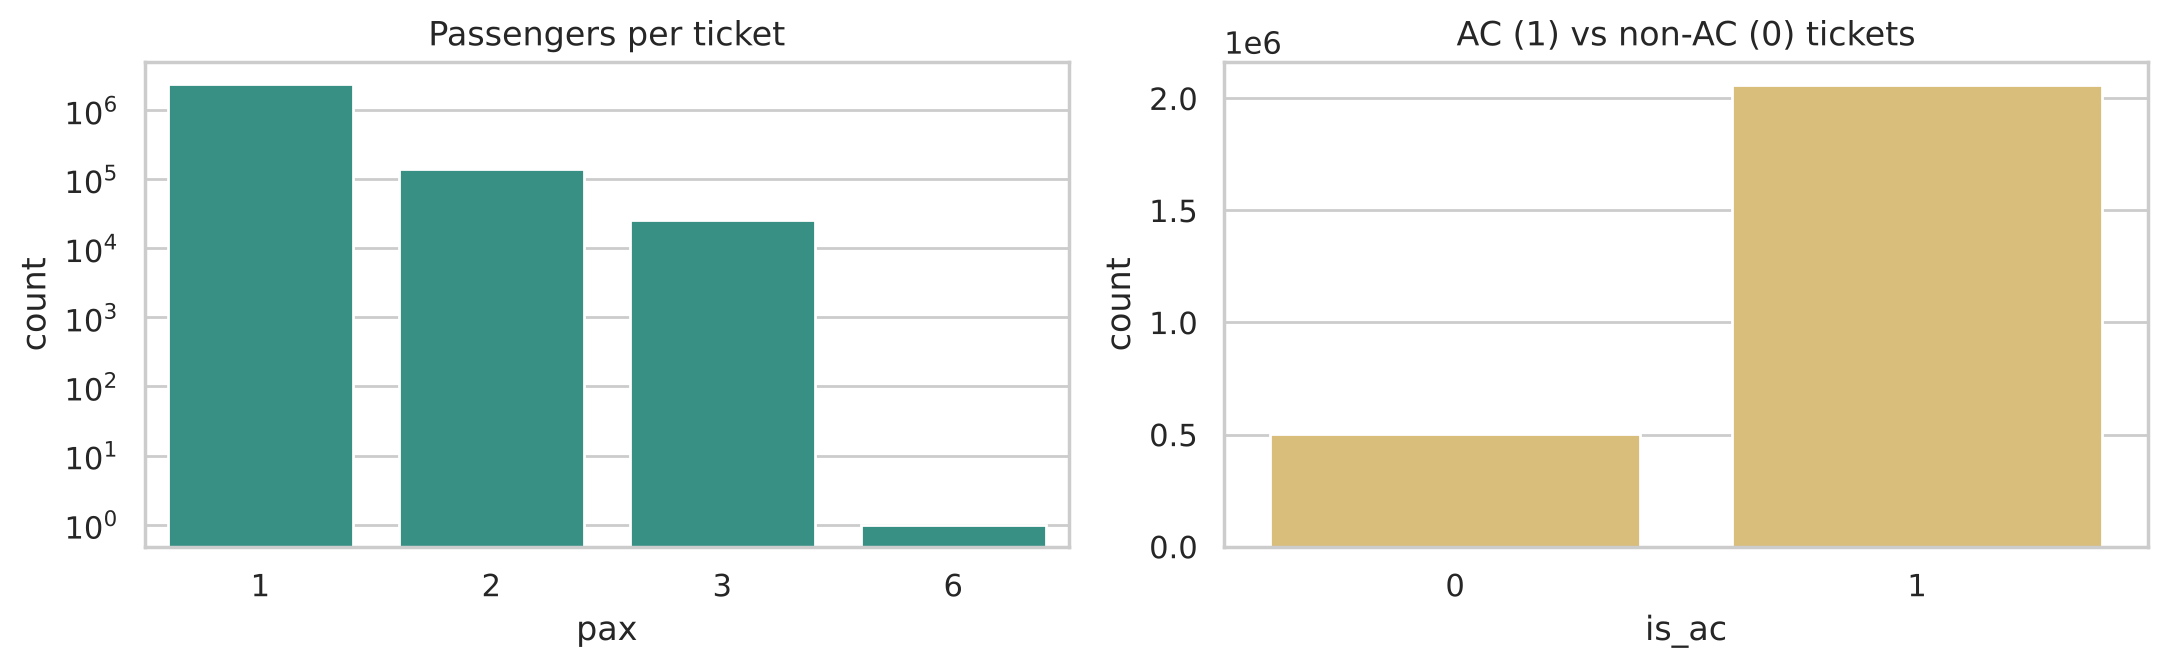

Share of tickets covering exactly 1 passenger: 93.4%


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.countplot(x="pax", data=df, ax=ax[0], color="#2a9d8f"); ax[0].set_title("Passengers per ticket"); ax[0].set_yscale("log")
sns.countplot(x="is_ac", data=df, ax=ax[1], color="#e9c46a"); ax[1].set_title("AC (1) vs non-AC (0) tickets")
plt.tight_layout(); plt.show()
print("Share of tickets covering exactly 1 passenger: %.1f%%" % (100 * (df.pax == 1).mean()))

## 3. Save to the database
`db.get_engine()` connects to the database and creates the database for us (`bus_crowd_real`). Then `db.save_table` writes the DataFrame
as a table. This takes a minute or two for 2.5 million rows.

In [6]:
engine = db.get_engine()
cols = ["pax", "amount", "vehicle", "start_name", "end_name", "route_raw", "ts", "is_ac", "date", "hour", "dow", "daytype"]
n = db.save_table(df[cols], "tickets", engine, index_cols=["date", "route_raw"])
print(f"saved {n:,} rows to table `tickets`")

saved 2,559,899 rows to table `tickets`


## 4. Explore with SQL
From here we let the **database** do the counting (`GROUP BY`) and use pandas / seaborn for the charts.

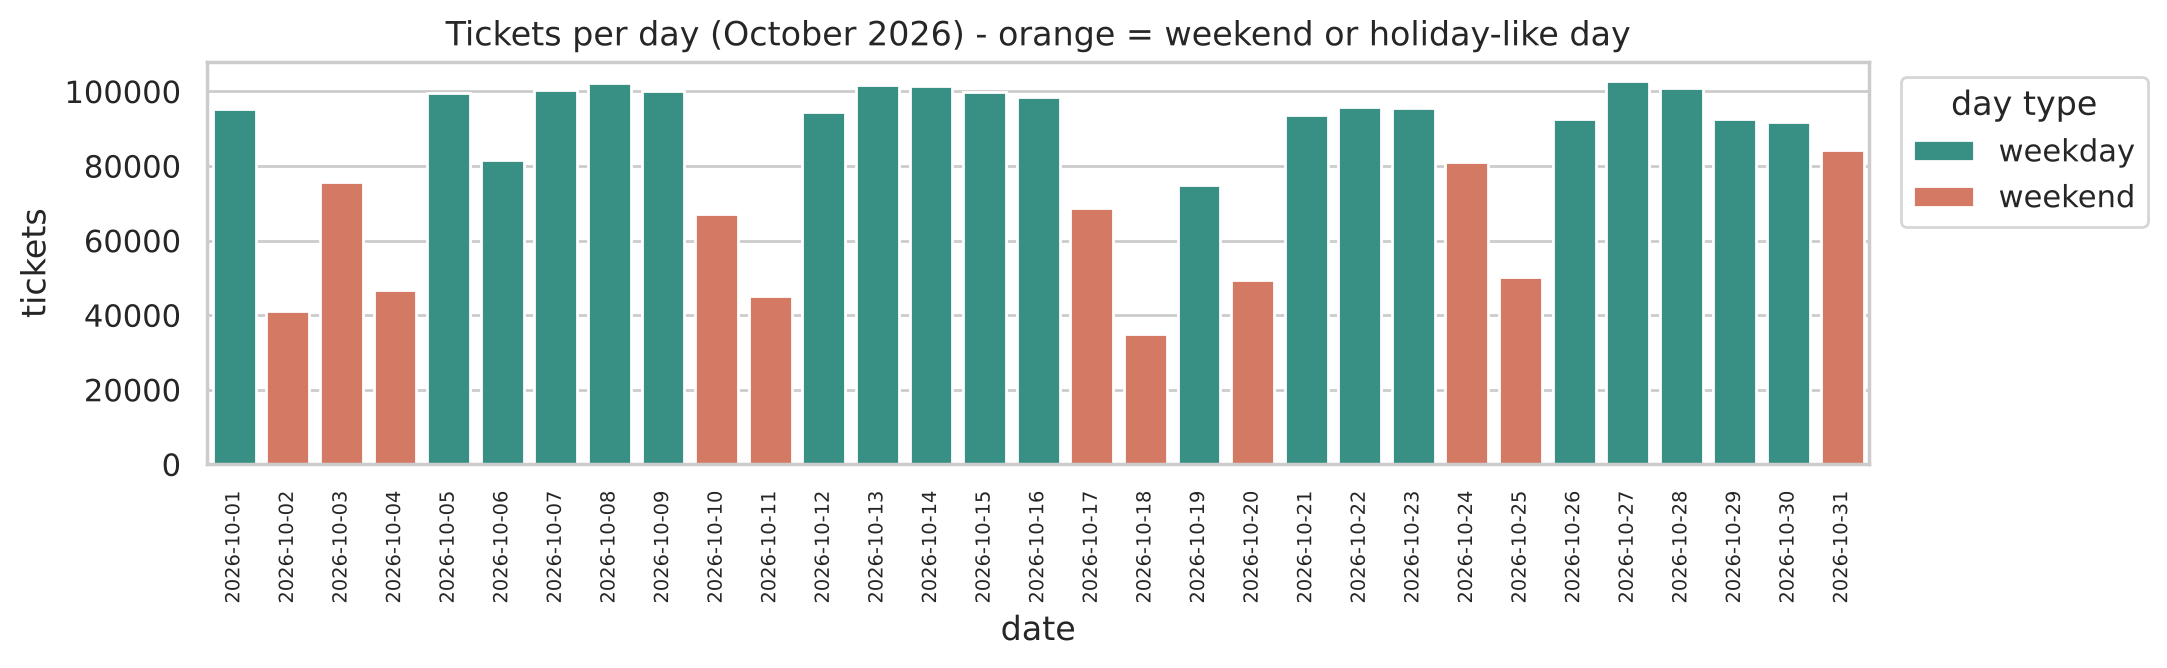

,count,mean,std,min,25%,50%,75%,max
daytype,,,,,,,,
weekday,20.0,95782.0,7051.0,74801.0,93401.0,97182.0,100508.0,102746.0
weekend,11.0,58569.0,17262.0,35009.0,45840.0,50161.0,72272.0,84185.0


In [7]:
daily = db.query('''
    SELECT date, MIN(dow) AS dow, MIN(daytype) AS daytype, COUNT(*) AS tickets, SUM(pax) AS passengers,
           ROUND(100 * AVG(vehicle IS NULL)) AS pct_no_vehicle
    FROM tickets GROUP BY date ORDER BY date
''', engine)
typical = daily.loc[daily.dow < 5, "tickets"].median()
daily["vs_typical_weekday"] = (daily.tickets / typical).round(2)

plt.figure(figsize=(11, 3.5))
sns.barplot(data=daily, x="date", y="tickets", hue="daytype", palette={"weekday": "#2a9d8f", "weekend": "#e76f51"}, dodge=False)
plt.xticks(rotation=90, fontsize=7); plt.title("Tickets per day (October 2026) - orange = weekend or holiday-like day")
plt.legend(title="day type", loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout()
plt.savefig(config.FIG / "01_daily_tickets.png", dpi=130); plt.show()
daily.groupby("daytype").tickets.describe().round(0)

## 4b. Unusual days
Two weekdays sell only about half the usual tickets, and three days around 17-19 October look different in another way.
We list them rather than guess.

In [8]:
daily["weekday_name"] = pd.to_datetime(daily.date).dt.day_name().str[:3]
odd = daily[(daily.dow < 5) & (daily.vs_typical_weekday < 0.9) | daily.date.isin(["2026-10-17", "2026-10-18", "2026-10-19"])]
print(f"Typical weekday: {typical:,.0f} tickets")
odd[["date", "weekday_name", "tickets", "vs_typical_weekday", "pct_no_vehicle", "daytype"]]

Typical weekday: 95,710 tickets


,date,weekday_name,tickets,vs_typical_weekday,pct_no_vehicle,daytype
1,2026-10-02,Fri,41016,0.43,47.0,weekend
5,2026-10-06,Tue,81592,0.85,51.0,weekday
16,2026-10-17,Sat,68836,0.72,35.0,weekend
17,2026-10-18,Sun,35009,0.37,15.0,weekend
18,2026-10-19,Mon,74801,0.78,38.0,weekday
19,2026-10-20,Tue,49375,0.52,44.0,weekend


**What we found**
- **2 Oct (Fri, 0.43x) and 20 Oct (Tue, 0.52x)** look like public holidays: 2 Oct is Gandhi Jayanti, and 20 Oct is very likely Dussehra (please check the calendar). They behave like Sundays, so `src/tickets.py` treats any weekday below
  60% of a normal weekday as a **holiday-like day** and files it under `daytype = weekend`. Otherwise they would drag the weekday averages down by about 5%.
- **17-19 Oct:** the share of tickets *without* a vehicle number drops from about 50% to 35%, 15% and 38%. Something changed in how tickets were recorded on those days.
  We cannot explain it from the data. It does not affect us, because the model does not use the vehicle number. 18 Oct is also the quietest Sunday (35k vs 45-50k on other Sundays) - we keep it but flag it as unexplained.
- Tuesday 6 Oct (0.85x) and Monday 19 Oct (0.78x) are lower but not extreme, so they stay as normal weekdays.

Days counted as weekday / weekend-or-holiday: {'weekday': 20, 'weekend': 11}


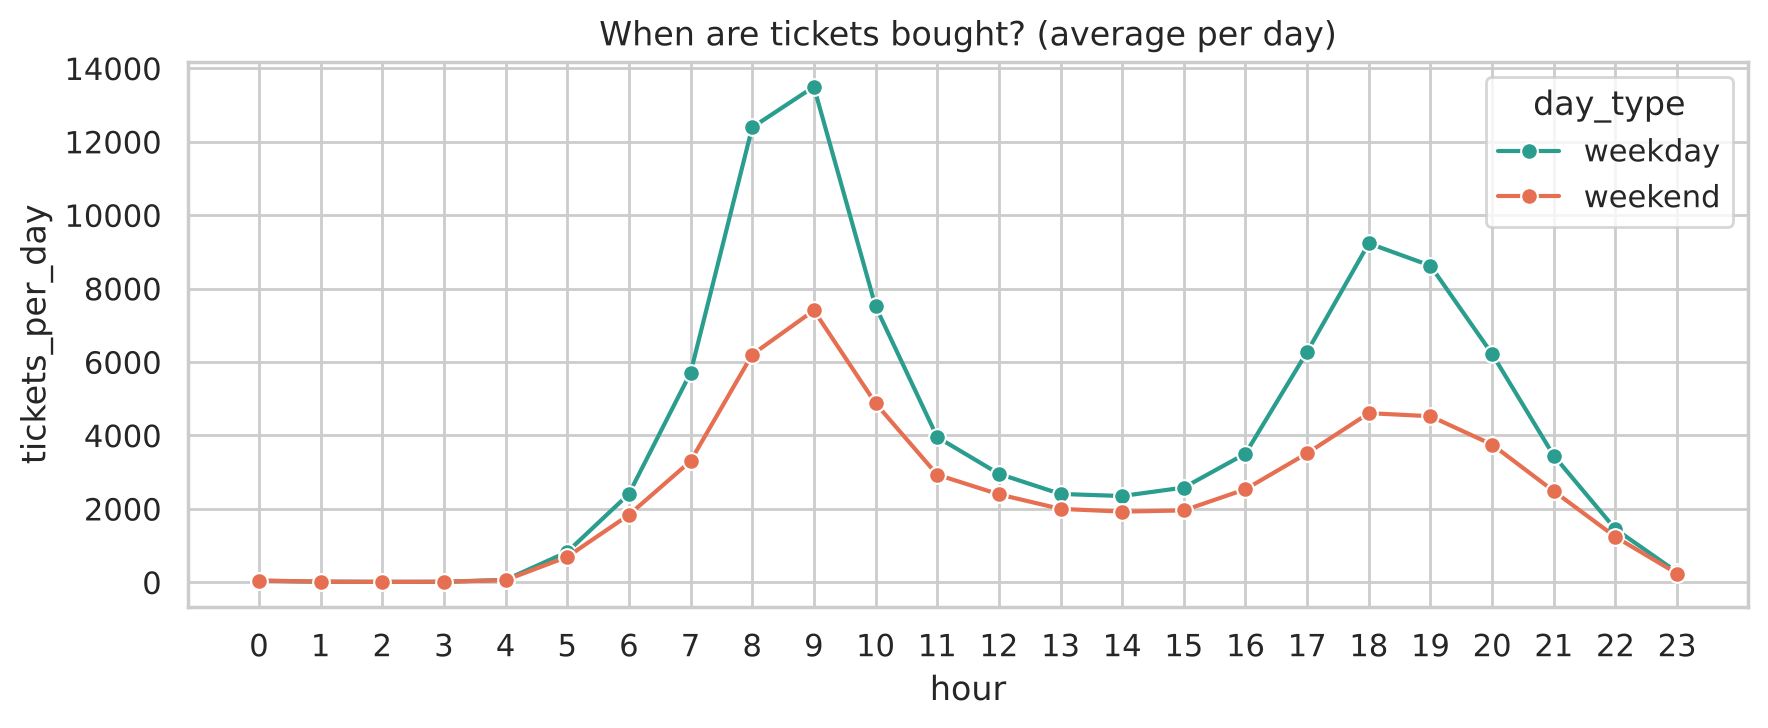

In [9]:
hourly = db.query('''
    SELECT hour, daytype AS day_type, COUNT(*) AS tickets
    FROM tickets GROUP BY hour, daytype ORDER BY hour
''', engine)
n_days = daily.daytype.value_counts()                         # how many weekdays / weekend days in the month
hourly["tickets_per_day"] = hourly.tickets / hourly.day_type.map(n_days)
print("Days counted as weekday / weekend-or-holiday:", n_days.to_dict())

plt.figure(figsize=(9, 3.8))
sns.lineplot(data=hourly, x="hour", y="tickets_per_day", hue="day_type", marker="o", palette={"weekday": "#2a9d8f", "weekend": "#e76f51"})
plt.xticks(range(0, 24)); plt.title("When are tickets bought? (average per day)"); plt.tight_layout()
plt.savefig(config.FIG / "01_hourly_tickets.png", dpi=130); plt.show()

Weekdays show a clear **morning peak (around 8-9)** and an evening peak, weekends are flatter. This is the daily rhythm the crowd model must reproduce.

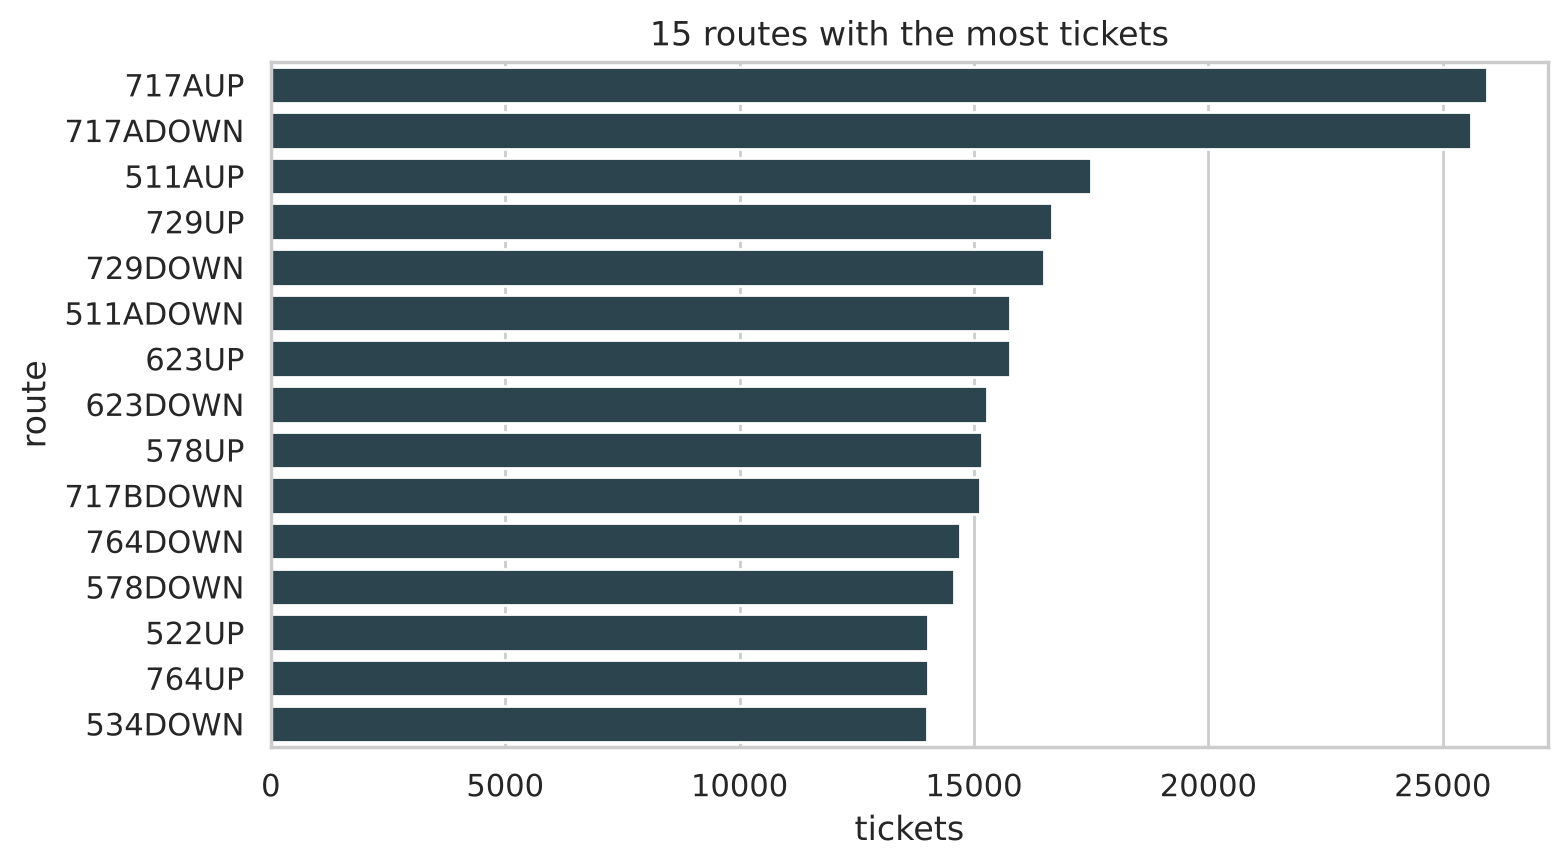

In [10]:
top = db.query('''
    SELECT route_raw AS route, COUNT(*) AS tickets, ROUND(AVG(is_ac), 2) AS share_ac
    FROM tickets GROUP BY route_raw ORDER BY tickets DESC LIMIT 15
''', engine)
plt.figure(figsize=(8, 4.5)); sns.barplot(data=top, y="route", x="tickets", color="#264653")
plt.title("15 routes with the most tickets"); plt.tight_layout(); plt.savefig(config.FIG / "01_top_routes.png", dpi=130); plt.show()

## 5. How concentrated is the data?
A few routes sell most of the tickets - so some routes will have thin data. We will handle that in notebook 03 (shrinkage).

In [11]:
per_route = df.groupby("route_raw", observed=True).size().sort_values(ascending=False)
share = per_route.cumsum() / per_route.sum()
print(f"Top 10% of routes ({int(len(per_route)*0.1)}) hold {share.iloc[int(len(per_route)*0.1)-1]*100:.0f}% of all tickets")
print(f"Routes with fewer than 100 tickets in the month: {(per_route < 100).sum()} of {len(per_route)}")

Top 10% of routes (225) hold 59% of all tickets
Routes with fewer than 100 tickets in the month: 794 of 2259


## 6. Is the missing vehicle number random?
If bus numbers were missing for **whole trips**, we would lose entire buses. If they are missing **ticket by ticket** (like a coin flip),
the remaining tickets still represent every bus. We test this in three ways.

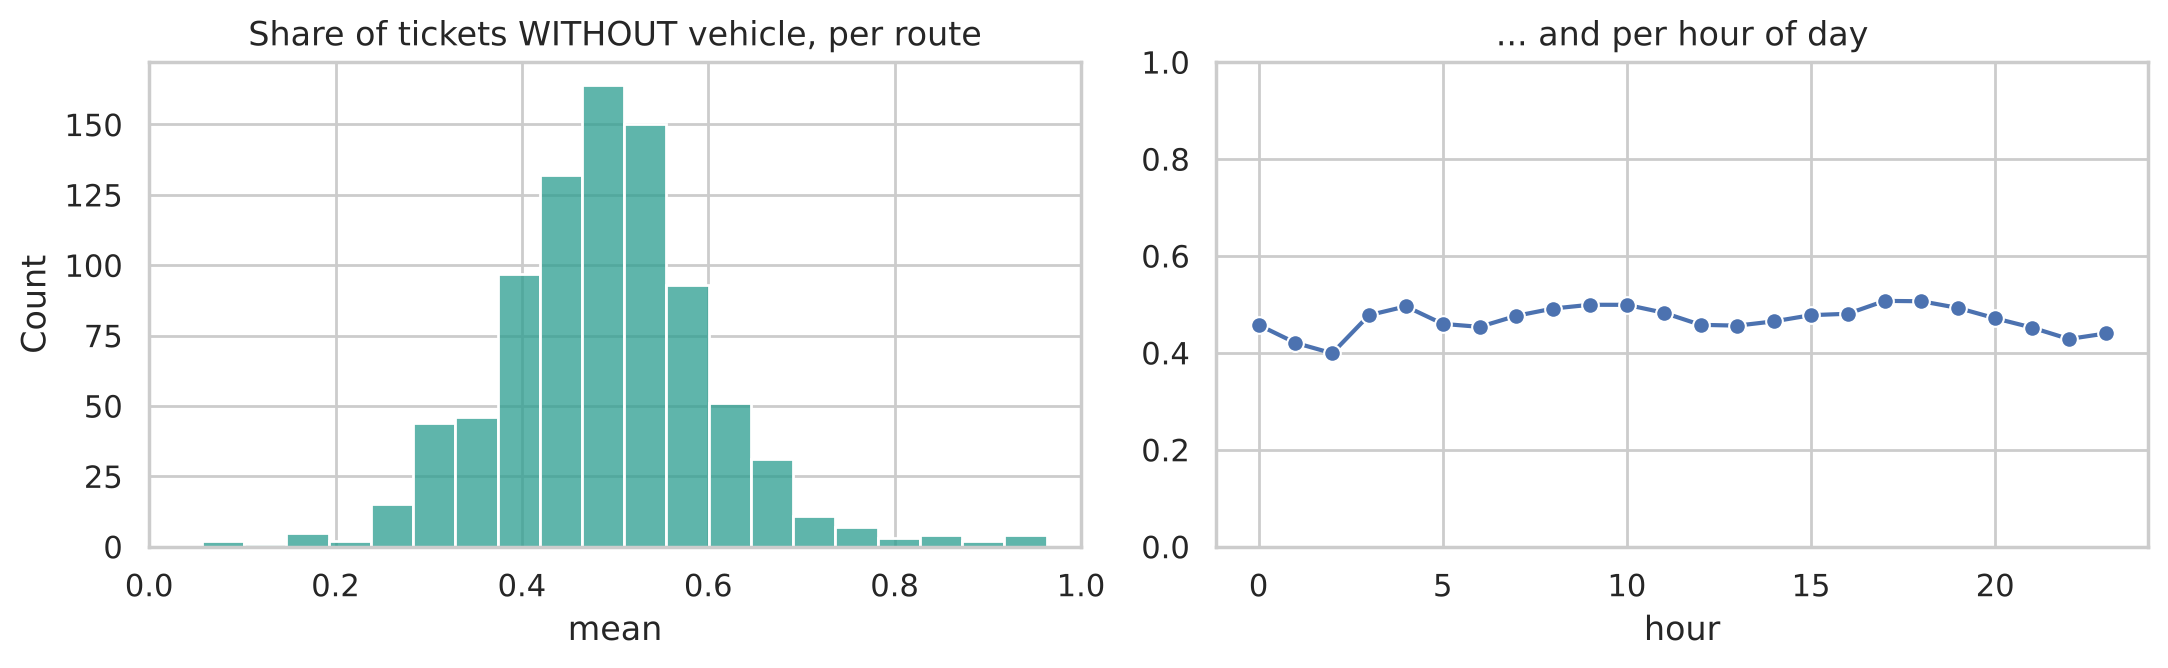

P(no vehicle | previous ticket had none)  = 0.528
P(no vehicle | previous ticket had one)   = 0.444


In [12]:
df["no_vehicle"] = df.vehicle.isna()
by_route = df.groupby("route_raw", observed=True).no_vehicle.agg(["mean", "size"])
by_route = by_route[by_route["size"] >= 500]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(by_route["mean"], bins=20, ax=ax[0], color="#2a9d8f"); ax[0].set_title("Share of tickets WITHOUT vehicle, per route"); ax[0].set_xlim(0, 1)
sns.lineplot(x=df.groupby("hour").no_vehicle.mean().index, y=df.groupby("hour").no_vehicle.mean().values, ax=ax[1], marker="o")
ax[1].set_ylim(0, 1); ax[1].set_title("... and per hour of day"); ax[1].set_xlabel("hour"); plt.tight_layout(); plt.show()

# runs test: if a ticket has no vehicle, is the NEXT ticket on the same route more likely to have none?
d = df.sort_values(["route_raw", "ts"])
prev = d.groupby("route_raw", observed=True).no_vehicle.shift()
print("P(no vehicle | previous ticket had none)  = %.3f" % d.loc[prev == True, "no_vehicle"].mean())
print("P(no vehicle | previous ticket had one)   = %.3f" % d.loc[prev == False, "no_vehicle"].mean())

**Reading the result**
- Almost every route sits near 50% missing, and so does every hour -> the gap is **not** tied to particular routes or times.
- If whole trips were missing, the two probabilities above would be close to 1 and 0. They are close to each other (about 0.53 vs 0.44) -> mostly **ticket-by-ticket** missingness.

**Decision:** we use **all** tickets, with or without a vehicle number. Direction comes from the route name (`UP`/`DOWN`), so the vehicle is not needed.
We confirm in notebook 03 that bus-by-bus trip reconstruction would not work anyway.

In [13]:
profile = {
    "tickets": int(len(df)), "days": int(df.date.nunique()), "holiday_like_days": detect_offdays(df).date.tolist(), "routes": int(df.route_raw.nunique()),
    "vehicles": int(df.vehicle.nunique()), "share_without_vehicle": round(float(df.no_vehicle.mean()), 4),
    "share_single_passenger": round(float((df.pax == 1).mean()), 4),
}
import json; (config.OUT / "01_data_profile.json").write_text(json.dumps(profile, indent=2)); profile

{'tickets': 2559899,
 'days': 31,
 'holiday_like_days': ['2026-10-02', '2026-10-20'],
 'routes': 2259,
 'vehicles': 6809,
 'share_without_vehicle': 0.4852,
 'share_single_passenger': 0.9344}

**Next:** `02_gtfs_and_stop_matching.ipynb` - read the bus timetable (GTFS) and link the typed stop names on tickets to real stops.